# Analyse exploratoire des données


## Importation des bibliothèques


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


## Chargement des données


In [4]:
data = pd.read_csv('../data/dataset.csv')

## Découverte des données


### Dimensions du dataset


In [3]:
print(f"Nombre de lignes : {data.shape[0]}")
print(f"Nombre de colonnes : {data.shape[1]}")

Nombre de lignes : 300153
Nombre de colonnes : 12


### Aperçu des données


In [5]:
data.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


### Informations générales


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 42.9 MB


### Types des variables


In [7]:
classification = pd.DataFrame({
    "Variable": [
        "airline", "flight", "source_city", "departure_time",
        "stops", "arrival_time", "destination_city",
        "class", "duration", "days_left", "price"
    ],
    "Nature": [
        "Nominale", "Nominale", "Nominale",
        "Ordinale", "Ordinale", "Ordinale",
        "Nominale", "Ordinale",
        "Continue", "Discrete", "Continue"
    ]
})
classification


,Variable,Nature
0,airline,Nominale
1,flight,Nominale
2,source_city,Nominale
3,departure_time,Ordinale
4,stops,Ordinale
5,arrival_time,Ordinale
6,destination_city,Nominale
7,class,Ordinale
8,duration,Continue
9,days_left,Discrete


### Valeurs manquantes


In [9]:
print(f"Total des valeurs manquantes : {data.isna().sum().sum()}")

Total des valeurs manquantes : 0


### Doublons


In [8]:
print(f"Nombre de lignes dupliquées : {data.duplicated().sum()}")

Nombre de lignes dupliquees : 0


### Statistiques descriptives des variables numériques

In [10]:
data[['price', 'duration', 'days_left']].describe().round(2)

,price,duration,days_left
count,300153.00,300153.00,300153.00
mean,20889.66,12.22,26.00
std,22697.77,7.19,13.56
min,1105.00,0.83,1.00
25%,4783.00,6.83,15.00
50%,7425.00,11.25,26.00
75%,42521.00,16.17,38.00
max,123071.00,49.83,49.00


## Analyse des distributions


### Distribution du prix


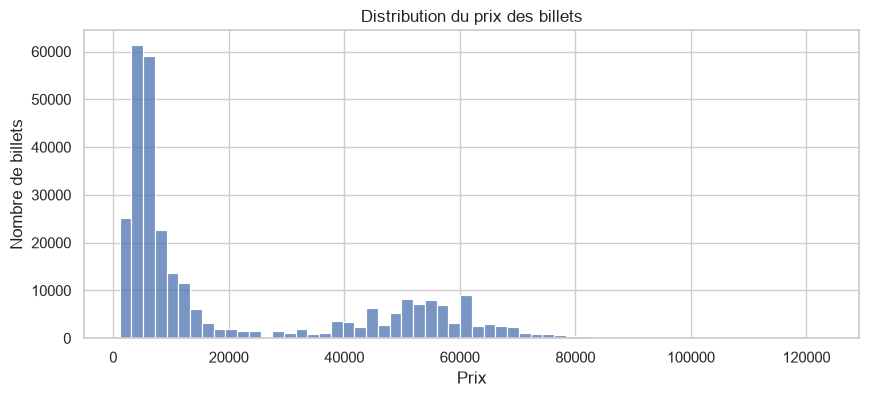

In [11]:
plt.figure(figsize=(10, 4))
sns.histplot(data=data, x="price", bins=60, color="#4C72B0")
plt.title("Distribution du prix des billets")
plt.xlabel("Prix")
plt.ylabel("Nombre de billets")
plt.show()

### Distribution de la durée et des jours avant le départ


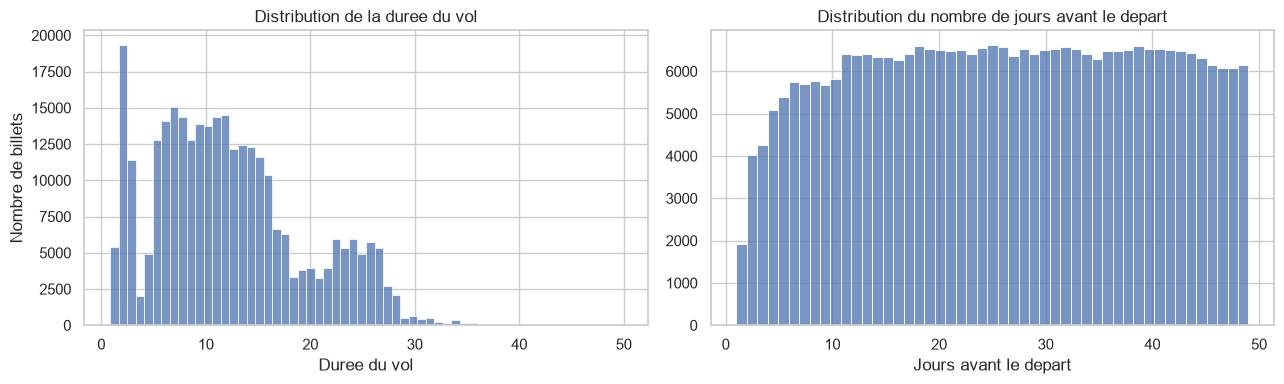

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=data, x="duration", bins=60, color="#4C72B0", ax=axes[0])
axes[0].set_title("Distribution de la durée du vol")
axes[0].set_xlabel("Durée du vol")
axes[0].set_ylabel("Nombre de billets")

sns.histplot(data=data, x="days_left", bins=49, color="#4C72B0", ax=axes[1])
axes[1].set_title("Distribution du nombre de jours avant le départ")
axes[1].set_xlabel("Jours avant le départ")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


### Asymétrie des distributions (Skewness)


In [13]:
print(f"Skewness de price : {data['price'].skew():.3f}")
print(f"Skewness de duration : {data['duration'].skew():.3f}")
print(f"Skewness de days_left : {data['days_left'].skew():.3f}")

Skewness de price : 1.061
Skewness de duration : 0.603
Skewness de days_left : -0.035


### Interprétation

`price` présente une asymétrie positive importante, tandis que `duration` présente une asymétrie positive modérée.  
`days_left` est presque symétrique, avec une skewness proche de 0.

Une transformation `log1p` pourra être appliquée à `duration` lors du prétraitement pour réduire son asymétrie.

### Dispersion des données

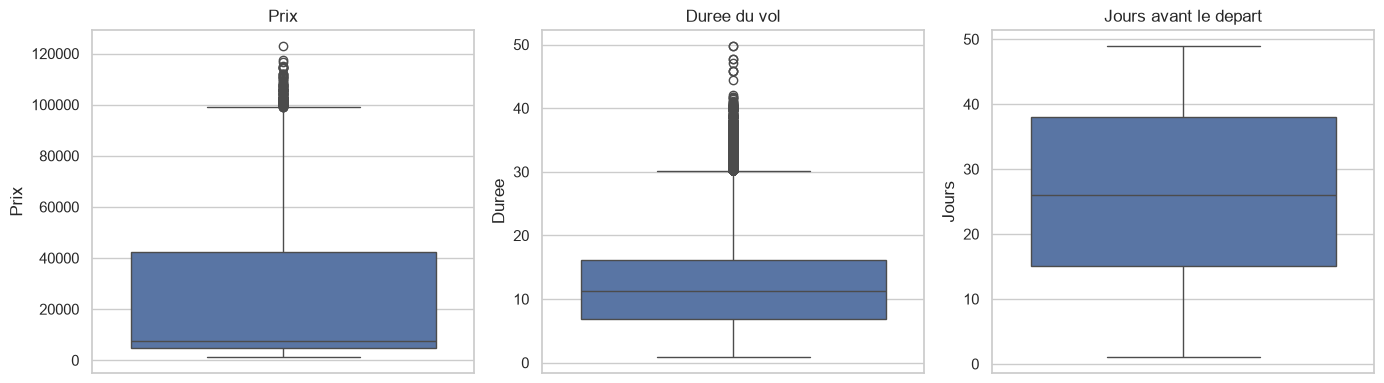

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.boxplot(data=data, y="price", color="#4C72B0", ax=axes[0])
axes[0].set_title("Prix")
axes[0].set_ylabel("Prix")

sns.boxplot(data=data, y="duration", color="#4C72B0", ax=axes[1])
axes[1].set_title("Durée du vol")
axes[1].set_ylabel("Durée")

sns.boxplot(data=data, y="days_left", color="#4C72B0", ax=axes[2])
axes[2].set_title("Jours avant le départ")
axes[2].set_ylabel("Jours")

plt.tight_layout()
plt.show()


## Analyse des variables catégorielles


### Fréquence des catégories


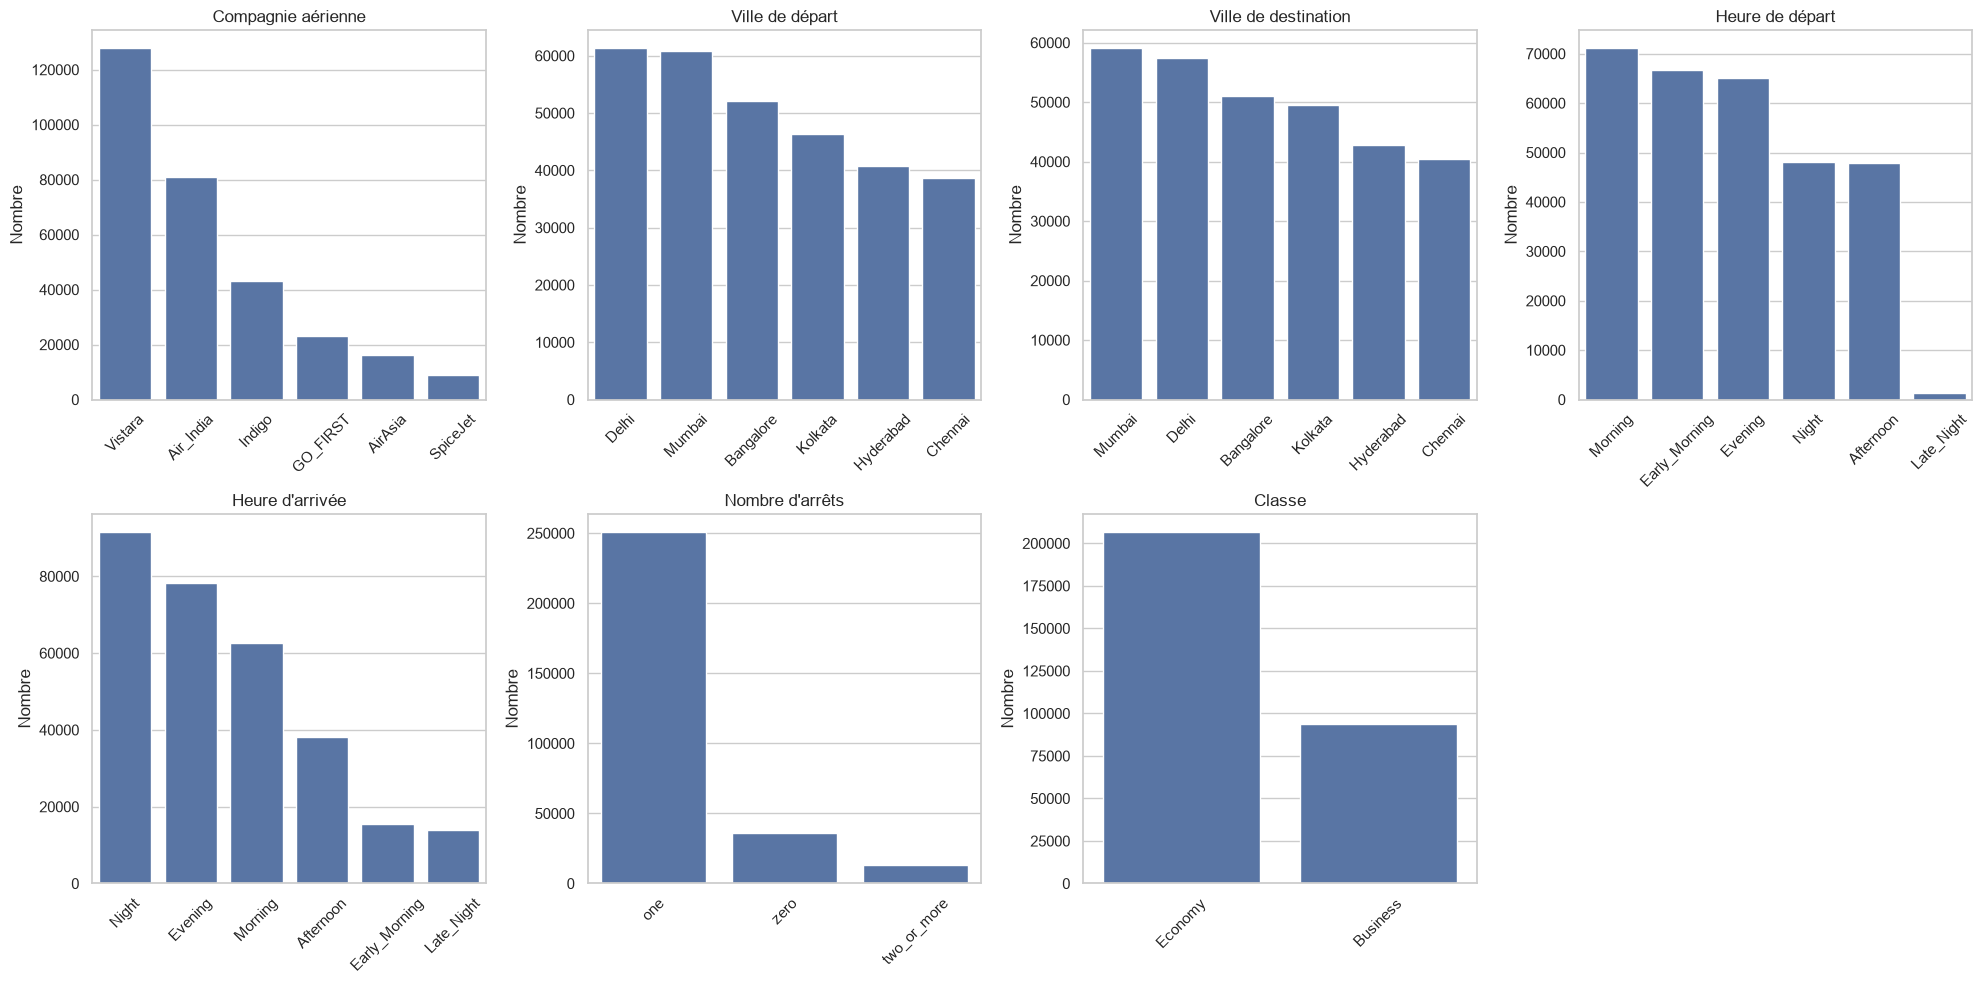

In [21]:
cols_cat = [
    "airline",
    "source_city",
    "destination_city",
    "departure_time",
    "arrival_time",
    "stops",
    "class",
]

titres = [
    "Compagnie aérienne",
    "Ville de départ",
    "Ville de destination",
    "Heure de départ",
    "Heure d'arrivée",
    "Nombre d'arrêts",
    "Classe",
]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))

axes = axes.flatten()

for i, col in enumerate(cols_cat):
    sns.countplot(data=data, x=col, order=data[col].value_counts().index, ax=axes[i])

    axes[i].set_title(titres[i])
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Nombre")
    axes[i].tick_params(axis="x", rotation=45)

axes[7].axis("off")

plt.tight_layout()
plt.show()

## Analyse de la relation avec le prix


### Prix selon la compagnie aérienne


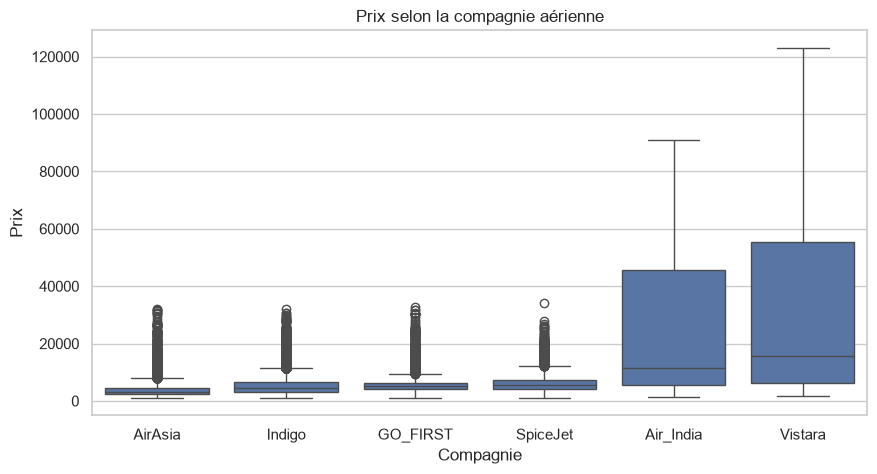

In [24]:
ordre_compagnies = data.groupby("airline")["price"].median().sort_values().index

plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x="airline", y="price", order=ordre_compagnies, color="#4C72B0")
plt.title("Prix selon la compagnie aérienne")
plt.xlabel("Compagnie")
plt.ylabel("Prix")
plt.show()


### Prix selon la classe


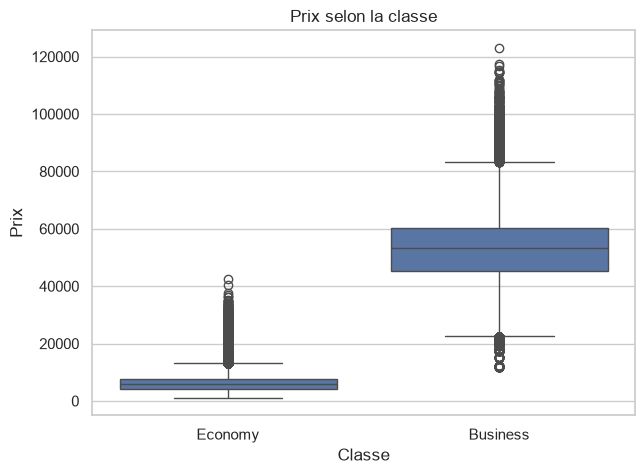

In [25]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="class", y="price", order=["Economy", "Business"], color="#4C72B0")
plt.title("Prix selon la classe")
plt.xlabel("Classe")
plt.ylabel("Prix")
plt.show()


### Prix selon le nombre d'escales


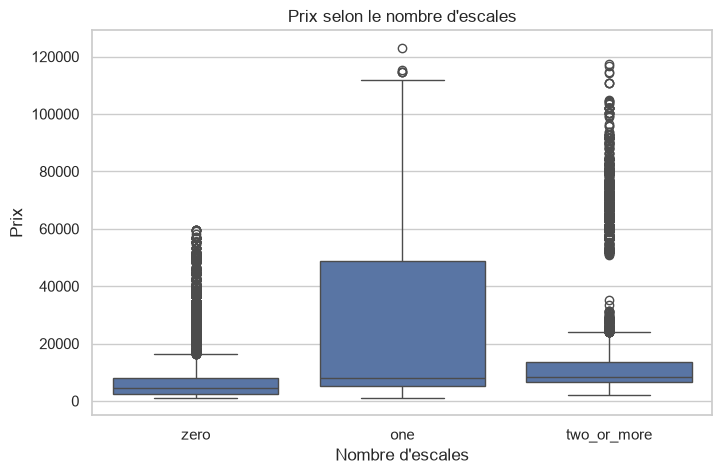

In [26]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x="stops", y="price",
            order=["zero", "one", "two_or_more"], color="#4C72B0")
plt.title("Prix selon le nombre d'escales")
plt.xlabel("Nombre d'escales")
plt.ylabel("Prix")
plt.show()


### Prix selon la durée du vol


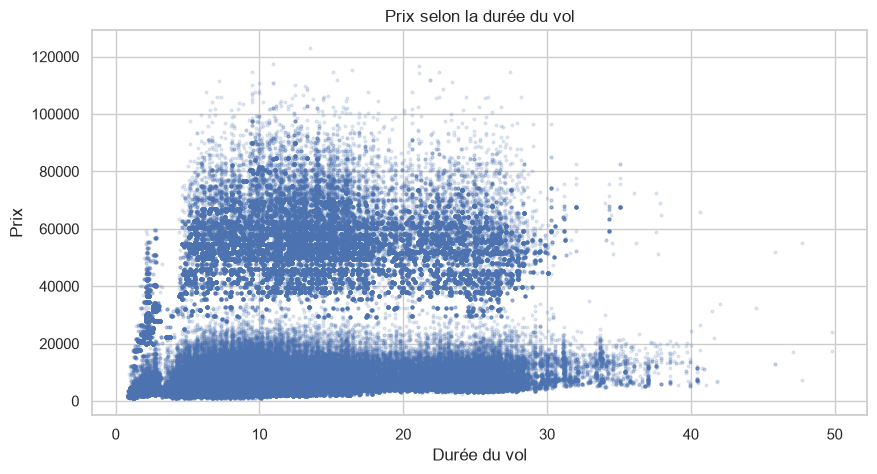

In [27]:
plt.figure(figsize=(10, 5))
plt.scatter(data["duration"], data["price"], s=4, alpha=0.15, color="#4C72B0")
plt.title("Prix selon la durée du vol")
plt.xlabel("Durée du vol")
plt.ylabel("Prix")
plt.show()


### Prix selon le nombre de jours avant le départ


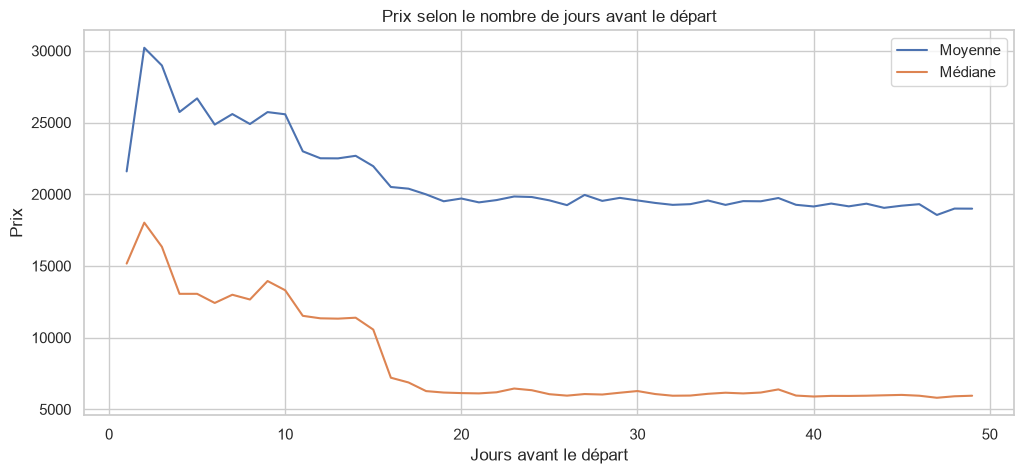

In [28]:
prix_par_jours = data.groupby("days_left")["price"].agg(["mean", "median"]).reset_index()

plt.figure(figsize=(12, 5))
sns.lineplot(data=prix_par_jours, x="days_left", y="mean", label="Moyenne")
sns.lineplot(data=prix_par_jours, x="days_left", y="median", label="Médiane")
plt.title("Prix selon le nombre de jours avant le départ")
plt.xlabel("Jours avant le départ")
plt.ylabel("Prix")
plt.legend()
plt.show()


## Conclusion de l'analyse

L'analyse exploratoire a permis de mieux comprendre la structure et les principales caractéristiques du dataset.

- Le dataset contient environ **300 000 observations**, sans valeurs manquantes ni doublons.
- La variable cible `price` présente une asymétrie positive importante, tandis que `duration` présente une asymétrie modérée et `days_left` est presque symétrique.
- Les variables catégorielles présentent des répartitions différentes selon les compagnies, les villes, les horaires, le nombre d'escales et la classe.
- La **classe**, la **compagnie aérienne** et le **nombre d'escales** semblent avoir une influence importante sur le prix des billets.
- La durée du vol présente également une relation avec le prix.
- Le nombre de jours avant le départ montre que le prix tend à évoluer à mesure que la date du vol approche.

Ces observations permettront de guider les étapes de prétraitement et de modélisation afin de construire un modèle capable de prédire le prix des billets d'avion.
